# Neft quyularında anomaliyaların aşkarlanması

Bu notebook `src/detector.py` modulundakı addımları bir-bir göstərir: data → təmizləmə → analiz → Isolation Forest → vizuallaşdırma → CSV hesabat.

Data sintetikdir, amma [3W Dataset](https://github.com/petrobras/3W)-dakı hadisə növlərinə (axın qeyri-sabitliyi, məhsuldarlığın sürətli itkisi, ştuserin qəfil daralması, ştuserdə duz çökməsi — 3W sinifləri 4–7) əsaslanır.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
import detector as d

pd.set_option('display.width', 160)

## 1. Data

4 quyu, 180 gün, saatlıq ölçmələr. `event_type` sütunu yalnız qiymətləndirmə üçündür — model onu görmür.

In [2]:
raw = pd.read_csv('../data/sample_data.csv')
print(raw.shape)
raw.head()

(17305, 8)


,timestamp,well_id,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct,event_type
0,2025-10-02 06:00:00,WELL-D,575.4,166.15,26.15,55.28,59.25,normal
1,2025-09-14 10:00:00,WELL-E,1656.1,243.40,48.96,76.76,12.03,normal
2,2025-10-10 03:00:00,WELL-F,900.3,199.49,34.65,62.43,36.91,normal
3,2025-10-10 21:00:00,WELL-G,1192.7,218.83,41.09,69.32,22.46,normal
4,2025-11-21 20:00:00,WELL-G,1166.7,217.09,40.01,69.84,23.17,normal


In [3]:
raw[d.METRICS].describe().round(1)

,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct
count,17202.0,17202.0,17201.0,17202.0,17202.0
mean,1125.2,208.2,40.0,66.8,31.5
std,417.1,28.1,152.1,7.4,17.5
min,-1.0,161.1,17.7,53.5,7.2
25%,653.8,173.9,32.8,59.4,15.5
50%,1041.1,206.6,39.9,67.0,31.8
75%,1403.6,231.7,46.4,72.5,53.9
max,1907.4,250.3,9999.0,79.8,120.0


Diqqət: `wellhead_pressure_bar` maksimumu 9999, `oil_rate_bpd` minimumu −1, `water_cut_pct` 120 — bunlar sensor xətalarıdır, prosesin özü deyil.

## 2. Təmizləmə

- dublikatlar silinir
- fiziki olaraq mümkün olmayan dəyərlər `NaN` edilir
- ≤3 saatlıq boşluqlar zamana görə interpolyasiya olunur, daha uzunları atılır

In [4]:
df, stats = d.clean_data(raw)
stats

{'rows_in': 17305,
 'duplicates_removed': 25,
 'missing_before': 515,
 'out_of_range_nulled': 12,
 'rows_dropped_long_gaps': 0,
 'rows_out': 17280}

In [5]:
d.describe_metrics(df)

oil_rate_bpd                        downhole_pressure_bar                       wellhead_pressure_bar                     wellhead_temp_c        \
                mean    std     min     max                  mean   std     min     max                  mean   std    min    max            mean   std   
well_id                                                                                                                                                   
WELL-D        589.24  32.63   404.6   751.1                167.55  2.71  161.08  174.55                 26.06  1.05  17.73  38.33           56.53  1.48   
WELL-E       1702.73  92.37  1155.8  1907.4                243.39  2.80  231.14  250.32                 48.87  0.63  44.73  61.07           76.51  1.49   
WELL-F        937.66  52.33   570.2  1089.4                200.46  3.01  182.56  207.28                 35.02  1.01  28.32  43.88           64.53  1.49   
WELL-G       1273.59  65.93   919.9  1611.1                221.52  2.74  214.95  230.54                 40.93  0.74  33.98  54.43           69.53  1.48   

                      water_cut_pct                      
           min    max          mean   std    min    max  
well_id                                                  
WELL-D   53.46  59.65         57.69  1.67  53.56  62.17  
WELL-E   72.64  79.77         11.70  1.67   7.25  15.92  
WELL-F   59.91  67.74         35.71  1.68  31.37  40.18  
WELL-G   65.64  72.96         20.71  1.67  16.65  24.75

## 3. Göstəricilərin analizi

In [6]:
df.groupby('event_type')[d.METRICS].mean().round(1)

,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct
event_type,,,,,
choke_restriction,855.8,214.4,48.5,64.7,30.2
choke_scaling,728.4,187.7,35.4,61.0,45.3
flow_instability,924.1,195.7,33.3,63.2,38.6
normal,1132.7,208.5,37.7,66.9,31.3
productivity_loss,1142.2,217.1,40.7,69.9,22.6


Bu hadisələr birinci layihədəkilərdən zəifdir: su payı demək olar dəyişmir, hasilat sıfıra düşmür. Ştuser daralmasında quyuağzı təzyiq qalxır, məhsuldarlıq itkisində isə quyudibi təzyiq düşür.

In [7]:
df[d.METRICS].corr().round(2)

,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct
oil_rate_bpd,1.00,0.98,0.98,0.97,-0.97
downhole_pressure_bar,0.98,1.00,0.99,0.98,-0.99
wellhead_pressure_bar,0.98,0.99,1.00,0.97,-0.98
wellhead_temp_c,0.97,0.98,0.97,1.00,-0.96
water_cut_pct,-0.97,-0.99,-0.98,-0.96,1.00


## 4. Isolation Forest

Hər metrik üçün 3 xüsusiyyət: son 7 günün medianından **sapma**, 1 saatlıq **dəyişmə**, 6 saatlıq **volatillik**. Hamısı hər quyu üçün ayrıca robust z-score ilə miqyaslanır.

In [8]:
X = d.build_features(df)
X.describe().T[['mean', 'std', 'min', 'max']].round(2).head(6)

,mean,std,min,max
oil_rate_bpd__level,-0.12,1.77,-23.10,17.02
oil_rate_bpd__diff,0.00,1.16,-15.82,16.94
oil_rate_bpd__vol,0.27,2.52,-2.86,41.76
downhole_pressure_bar__level,-0.04,1.26,-16.89,7.53
downhole_pressure_bar__diff,0.00,1.01,-4.68,12.98
downhole_pressure_bar__vol,0.10,1.19,-2.73,28.43


In [9]:
result = d.detect(df, contamination=0.025)
result['is_anomaly'].value_counts()

is_anomaly
False    16848
True       432
Name: count, dtype: int64

In [10]:
d.evaluate(result)

{'precision': np.float64(0.7268518518518519),
 'recall': np.float64(0.6652542372881356),
 'events_detected': '10/10'}

In [11]:
result[result.event_type != 'normal'].groupby('event_type')['is_anomaly'].mean().round(2).rename('tutulma payı')

event_type
choke_restriction    0.92
choke_scaling        0.50
flow_instability     0.94
productivity_loss    0.62
Name: tutulma payı, dtype: float64

In [12]:
pd.crosstab(result['event_type'], result['is_anomaly'], margins=True)

is_anomaly,False,True,All
event_type,,,
choke_restriction,2,22,24
choke_scaling,107,109,216
flow_instability,8,116,124
normal,16690,118,16808
productivity_loss,41,67,108
All,16848,432,17280


## 5. Vizuallaşdırma

Mavi xətt — normal ölçmələr, qırmızı nöqtələr — şübhəli ölçmələr, sarı zolaq — dataya əlavə olunmuş real hadisə.

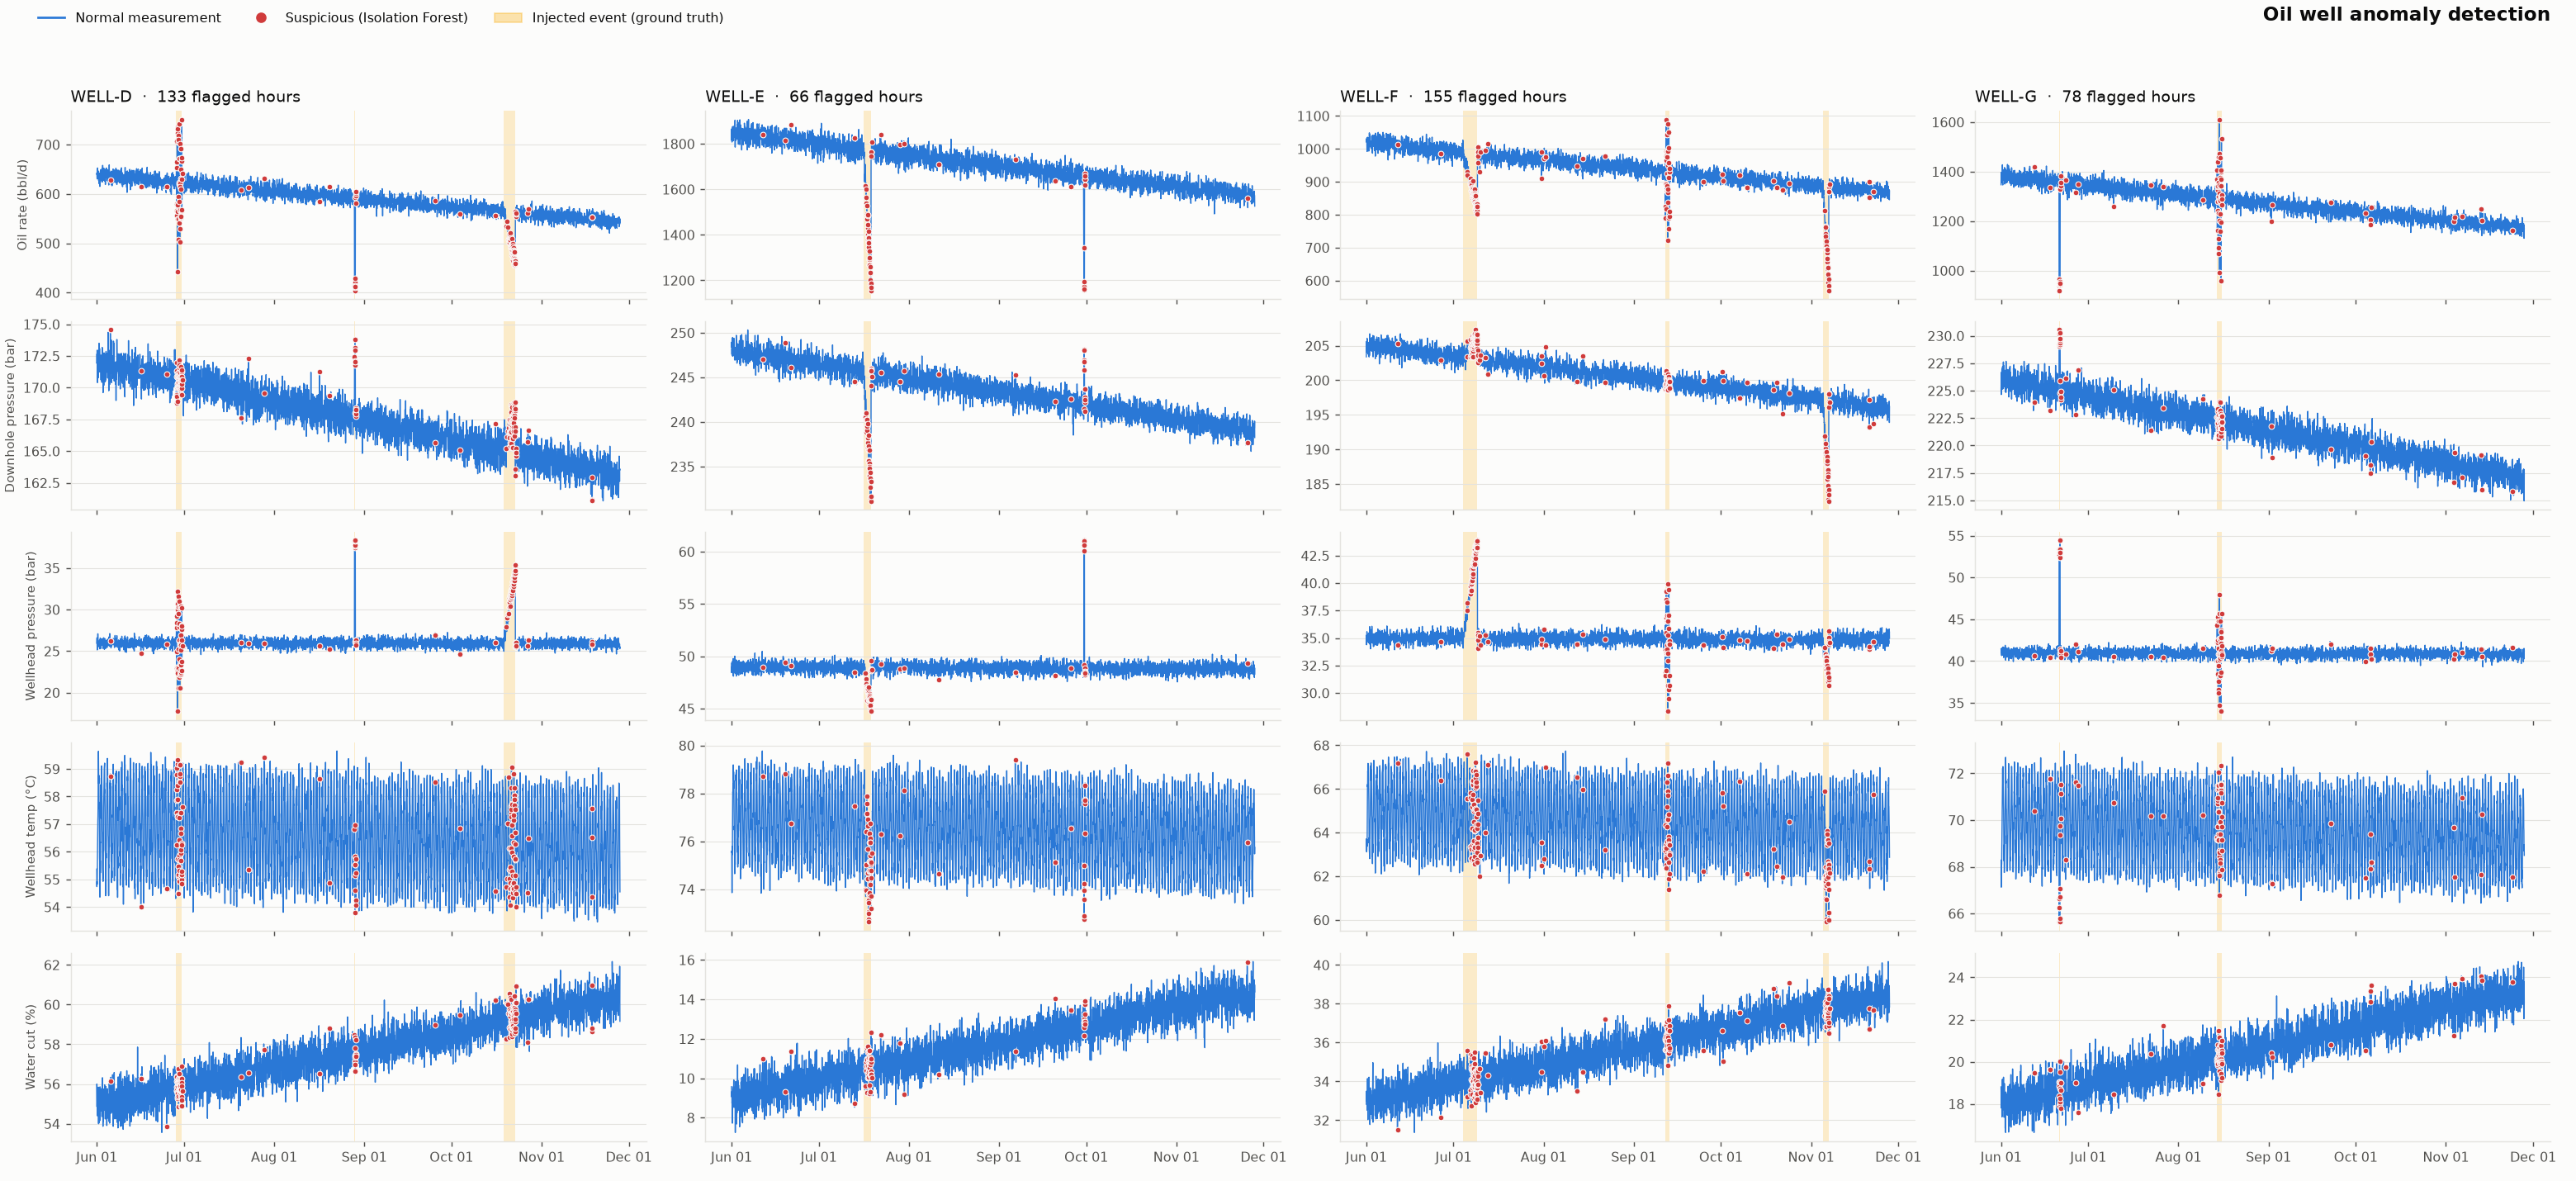

In [13]:
d.plot_results(result, d.OUTPUT_DIR / 'anomaly_plot.png')
Image(str(d.OUTPUT_DIR / 'anomaly_plot.png'))

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for flag, color, label in [(False, d.SERIES, 'normal'), (True, d.ANOMALY, 'şübhəli')]:
    ax.hist(result.loc[result['is_anomaly'] == flag, 'anomaly_score'], bins=60, color=color, alpha=0.8, label=label)
ax.set_xlabel('anomaly score (yüksək = daha qeyri-adi)'); ax.set_ylabel('saat sayı')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()

/var/folders/n8/8xljmx8d51g7vdyqlnczfk1r0000gn/T/ipykernel_23302/2039108769.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Hesabat: hansı müşahidələr araşdırılmalıdır

In [15]:
observations, episodes = d.build_report(result)
observations.to_csv(d.OUTPUT_DIR / 'suspicious_observations.csv', index=False)
episodes.to_csv(d.OUTPUT_DIR / 'anomaly_episodes.csv', index=False)
episodes

,episode_id,well_id,start,end,flagged_hours,max_score,top_reason
0,72,WELL-G,2025-06-20 23:00:00,2025-06-21 12:00:00,14,0.7681,wellhead_pressure_bar volatility ↑ (z=+37.5); ...
1,38,WELL-E,2025-09-30 04:00:00,2025-09-30 14:00:00,11,0.7567,wellhead_pressure_bar volatility ↑ (z=+35.3); ...
2,10,WELL-D,2025-08-28 16:00:00,2025-08-29 03:00:00,12,0.7409,wellhead_pressure_bar volatility ↑ (z=+37.0); ...
3,80,WELL-G,2025-08-14 07:00:00,2025-08-16 00:00:00,42,0.7021,wellhead_pressure_bar volatility ↑ (z=+31.1); ...
4,4,WELL-D,2025-06-28 09:00:00,2025-06-30 10:00:00,48,0.7015,wellhead_pressure_bar volatility ↑ (z=+44.8); ...
...,...,...,...,...,...,...,...
87,74,WELL-G,2025-06-26 18:00:00,2025-06-26 18:00:00,1,0.4950,wellhead_pressure_bar ↑ (z=+2.7); oil_rate_bpd...
88,7,WELL-D,2025-07-28 14:00:00,2025-07-28 14:00:00,1,0.4945,oil_rate_bpd change ↑ (z=+3.5); oil_rate_bpd v...
89,92,WELL-G,2025-11-24 00:00:00,2025-11-24 00:00:00,1,0.4945,wellhead_pressure_bar change ↑ (z=+2.8); downh...
90,51,WELL-F,2025-08-01 00:00:00,2025-08-01 00:00:00,1,0.4944,wellhead_pressure_bar volatility ↑ (z=+3.1); w...


In [16]:
observations.head(10)

,episode_id,priority,timestamp,well_id,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct,anomaly_score,reason
13439,72,high,2025-06-20 23:00:00,WELL-G,937.6,229.09,53.08,66.26,19.03,0.7681,wellhead_pressure_bar volatility ↑ (z=+37.5); ...
7229,38,high,2025-09-30 05:00:00,WELL-E,1177.1,248.18,60.85,72.76,12.83,0.7567,wellhead_pressure_bar volatility ↑ (z=+35.3); ...
2128,10,high,2025-08-28 16:00:00,WELL-D,413.9,172.41,38.31,56.82,58.46,0.7409,wellhead_pressure_bar volatility ↑ (z=+37.0); ...
13441,72,high,2025-06-21 01:00:00,WELL-G,919.9,230.54,53.03,65.66,18.39,0.7388,wellhead_pressure_bar volatility ↑ (z=+52.2); ...
13440,72,high,2025-06-21 00:00:00,WELL-G,949.9,229.19,53.37,66.64,17.90,0.7381,wellhead_pressure_bar volatility ↑ (z=+48.8); ...
13442,72,high,2025-06-21 02:00:00,WELL-G,966.7,230.18,52.71,66.26,18.84,0.7328,wellhead_pressure_bar volatility ↑ (z=+48.7); ...
7231,38,high,2025-09-30 07:00:00,WELL-E,1159.2,245.85,60.05,73.58,12.15,0.7281,wellhead_pressure_bar volatility ↑ (z=+47.6); ...
2130,10,high,2025-08-28 18:00:00,WELL-D,420.2,172.11,37.67,55.82,57.43,0.7241,wellhead_pressure_bar volatility ↑ (z=+48.0); ...
13443,72,high,2025-06-21 03:00:00,WELL-G,955.9,229.24,52.37,65.76,20.02,0.7228,wellhead_pressure_bar volatility ↑ (z=+37.2); ...
2131,10,high,2025-08-28 19:00:00,WELL-D,429.0,173.17,37.91,55.54,56.97,0.7176,wellhead_pressure_bar volatility ↑ (z=+44.9); ...


### Epizod uzunluğu

Qısa (1–2 saatlıq) epizodlar əsasən küydür, real hadisələr uzun epizodlar verir.

In [17]:
truth = [result[(result.well_id == w) & result.timestamp.between(s, e)].event_type.ne('normal').any()
         for w, s, e in zip(episodes.well_id, episodes.start, episodes.end)]
episodes.assign(real_event=truth).groupby('real_event')['flagged_hours'].describe()

,count,mean,std,min,25%,50%,75%,max
real_event,,,,,,,,
False,70.0,1.071429,0.259399,1.0,1.0,1.0,1.00,2.0
True,22.0,16.227273,20.090111,1.0,1.0,2.0,33.75,57.0


## Nəticə

- 10 hadisənin hamısı ən azı qismən aşkarlandı, amma saat səviyyəsində recall 0.67-dir.
- Qəfil dəyişikliklər (ştuser daralması, axın qeyri-sabitliyi) >90% tutulur.
- Yavaş dəyişikliklər (ştuserdə duz çökməsi ~50%, məhsuldarlıq itkisi ~60%) çətindir: 7 günlük baza xətti onlara uyğunlaşır.
- Yalançı epizodlar demək olar hamısı 1–2 saatlıqdır, ona görə ≥3 saatlıq epizodlara fokuslanmaq səmərəlidir.